# Clasificación de textos en Esperanto — Categoría: **Cultura**
### Minería de Textos · 4º INF-A · CUNEF Universidad · Curso 2026/2027

**Autora:** Lucía Molina Paños

**Repositorio del dataset:** https://github.com/LuciaMoliina/practica-esperanto-cultura

**Subcategorías elegidas:** 🎬 cine (*kino*) · 🎵 música (*muziko*) · 📚 literatura (*literaturo*)

---

Este cuaderno construye, de principio a fin, un sistema capaz de **clasificar textos en Esperanto por temática**:

| Fase | Qué hacemos | Técnicas de clase |
|---|---|---|
| **1. Dataset** | Descargamos artículos de la Wikipedia en Esperanto (*Vikipedio*), los dividimos en párrafos y generamos un CSV etiquetado. | API REST, `requests`, JSON, `pandas` |
| **2. NLP** | Programamos desde cero un modelo de NLP para Esperanto basado en reglas, con un API parecido al de spaCy (`nlp(texto)` → `Doc` → `Token`). | Tokenización, lematización, POS-tagging, stop-words |
| **3. Clasificación** | Vectorizamos los párrafos (one-hot + media), entrenamos y evaluamos clasificadores, y clasificamos páginas web reales. | Vectorización, `scikit-learn`, web scraping con `BeautifulSoup` |

**Índice**
0. Configuración
1. Fase 1 — Dataset
2. Fase 2 — Modelo de NLP para Esperanto
3. Fase 3 — Clasificación
4. Clasificación de páginas web
5. Conclusiones

## 0. Configuración

Todos los parámetros del cuaderno están en esta celda para que se puedan cambiar fácilmente.

- `GENERAR_DATASET = False` (**valor por defecto**) → se usa el dataset ya generado y subido a nuestro repositorio público de GitHub (`DATASET_URL`). Así los resultados son exactamente los comentados en las conclusiones y la ejecución tarda segundos.
- `GENERAR_DATASET = True` → el dataset se vuelve a generar desde la Wikipedia (tarda unos 3 minutos). Como la Wikipedia se edita con el tiempo, los números pueden variar ligeramente.

En cualquiera de los dos casos, si la opción elegida falla (por ejemplo, Wikipedia no responde), el cuaderno intenta automáticamente la otra, para que la ejecución no se interrumpa.

Se fija una **semilla** (`SEMILLA = 42`) para que los resultados sean reproducibles.

In [1]:
# ---------------------------------------------------------------
# Librerías (todas vistas en clase y preinstaladas en Google Colab)
# ---------------------------------------------------------------
import re
import time
import json
import random
import unicodedata
from collections import Counter
from urllib.parse import urlparse
from urllib.robotparser import RobotFileParser

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)

# ---------------------------------------------------------------
# Parámetros de ejecución
# ---------------------------------------------------------------
GENERAR_DATASET = False  # True: generar desde Wikipedia | False: descargar el CSV de GitHub
USUARIO_GITHUB = "LuciaMoliina"
REPOSITORIO_GITHUB = "practica-esperanto-cultura"
FICHERO_DATASET = "dataset_cultura_eo.csv"
DATASET_URL = f"https://raw.githubusercontent.com/{USUARIO_GITHUB}/{REPOSITORIO_GITHUB}/main/{FICHERO_DATASET}"

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# Cabecera HTTP con la que nos identificamos ante los servidores. Wikimedia pide que los
# programas incluyan una forma de contacto (aquí, la URL del repositorio del proyecto).
CABECERAS = {"User-Agent": f"PracticaMineriaTextosCUNEF/1.0 "
                           f"(https://github.com/{USUARIO_GITHUB}/{REPOSITORIO_GITHUB}; proyecto universitario)"}

pd.set_option("display.max_colwidth", 120)
print("Configuración cargada. Generar dataset:", GENERAR_DATASET)

Configuración cargada. Generar dataset: False


---
## 1. Fase 1 — Dataset

### 1.1 Elección de temáticas
Hemos elegido la categoría **Cultura** con tres subcategorías **semánticamente cercanas**: **cine**, **música** y **literatura**. Son cercanas porque comparten mucho vocabulario (*verko* = obra, *aŭtoro* = autor, *premio*, *festivalo*, *teatro*…), y además se mezclan entre sí (bandas sonoras, novelas adaptadas al cine, poemas cantados). Esto hace que el problema **no sea trivial**.

### 1.2 Fuente de datos: API de la Wikipedia en Esperanto
Usamos la **API REST de MediaWiki** (`https://eo.wikipedia.org/w/api.php`), vista en el tema de APIs. Hacemos dos tipos de petición `GET`:

1. `list=categorymembers` → nos da los **títulos de los artículos** que pertenecen a una categoría (por ejemplo `Kategorio:Kino`).
2. `prop=extracts&explaintext=1` → nos da el **texto plano** de un artículo, ya sin HTML ni marcado wiki.

> **¿Por qué no usamos la función de ejemplo `WikiPage` del repositorio guía?** Usamos la misma API de MediaWiki, pero con tres funciones propias muy sencillas porque (1) necesitamos **listar los artículos de una categoría**, cosa que `WikiPage` no hace (busca artículos por título), y (2) así el cuaderno **no depende de instalar una librería externa**, lo que lo hace más autocontenido y robusto ante fallos. El enunciado permite usar cualquier fuente de datos.

Para cada clase elegimos unas categorías "semilla" de la Wikipedia:

| Clase | Categorías de Vikipedio usadas |
|---|---|
| `cine` | Kino, Filmoj, Filmĝenroj, Kina terminologio, Kinarto, Akademia Premio por plej bona filmo, Sciencfikciaj filmoj, Dramaj filmoj |
| `musica` | Muziko, Muzikaj instrumentoj, Komponistoj |
| `literatura` | Literaturo, Romanoj, Poezio, Literaturaj ĝenroj |

**Decisiones de diseño:**
- **Etiquetado:** cada párrafo hereda la etiqueta de la categoría de la que sale su artículo (etiquetado *débil* o automático).
- Si un artículo aparece en categorías de **dos clases distintas** (p. ej. *Rolulo* = personaje está en Kino y en Literaturo) **lo descartamos**, porque su etiqueta sería ambigua.
- Excluimos del dataset los artículos que usaremos después para probar el clasificador con páginas web (para no "hacer trampa").
- Máximo de párrafos por artículo (`MAX_PARRAFOS_POR_ARTICULO`) para que un artículo muy largo no domine una clase.
- Descartamos los artículos muy cortos (esbozos) y las secciones de **argumento** (*Intrigo*, *Enhavo*...): en una primera versión vimos que los resúmenes de argumento de películas y novelas son casi idénticos (personajes, familia, viajes...) y el modelo aprendía a asociar palabras como *patro* (padre) con el cine.
- Pausa entre peticiones y reintentos si el servidor responde `429 Too Many Requests` (ética del web mining: no saturar el servidor).

In [2]:
# Categorías de Vikipedio que usamos como fuente de cada clase
CATEGORIAS = {
    "cine":       ["Kino", "Filmoj", "Filmĝenroj", "Kina terminologio", "Kinarto",
                   "Akademia Premio por plej bona filmo", "Sciencfikciaj filmoj", "Dramaj filmoj"],
    "musica":     ["Muziko", "Muzikaj instrumentoj", "Komponistoj"],
    "literatura": ["Literaturo", "Romanoj", "Poezio", "Literaturaj ĝenroj"],
}

# Artículos reservados para la prueba con páginas web (Fase 3): no pueden estar en el dataset
ARTICULOS_EXCLUIDOS = {"Angoroj", "Ĵazo", "Hamleto"}

OBJETIVO_PARRAFOS_POR_CLASE = 450   # dejamos de descargar una clase al llegar a esta cifra
MAX_PARRAFOS_POR_ARTICULO = 8       # para que ningún artículo domine su clase
MIN_PALABRAS_PARRAFO = 12           # párrafos más cortos suelen ser títulos, listas o pies de foto
LONGITUD_MINIMA_ARTICULO = 3000     # bytes: descartamos esbozos muy cortos (dan 0-1 párrafos)
PAUSA_SEGUNDOS = 0.3                # pausa entre peticiones para no saturar la API

API_WIKIPEDIA = "https://eo.wikipedia.org/w/api.php"

# Secciones a partir de las cuales ya no hay texto útil (referencias, enlaces...)
SECCIONES_FINALES = {"referencoj", "notoj", "piednotoj", "eksteraj ligiloj", "vidu ankaŭ",
                     "fontoj", "bibliografio", "literaturo", "rilataj artikoloj"}

# Secciones de argumento: narran la historia (personajes, familia, viajes...) y no hablan
# del cine o de la literatura en sí. Un argumento de película y uno de novela son casi iguales.
SECCIONES_ARGUMENTO = {"intrigo", "enhavo", "resumo", "rakonto", "argumento", "fabelo", "agado"}

In [3]:
def llamar_api(parametros, reintentos=5):
    # Hace una petición GET a la API de Wikipedia y devuelve el JSON (o None si falla).
    # Si el servidor responde 429 (demasiadas peticiones) esperamos y lo volvemos a intentar.
    parametros = dict(parametros, format="json", formatversion=2)
    for intento in range(reintentos):
        try:
            respuesta = requests.get(API_WIKIPEDIA, params=parametros,
                                     headers=CABECERAS, timeout=20)
            if respuesta.status_code == 429:
                # El servidor nos dice cuánto esperar en la cabecera Retry-After
                retry_after = respuesta.headers.get("Retry-After", "0")
                espera = max(int(retry_after) if retry_after.isdigit() else 0, 5 * (intento + 1))
                print(f"   ⚠ API saturada (429). Esperamos {espera} s...")
                time.sleep(espera)
                continue
            respuesta.raise_for_status()
            return respuesta.json()
        except requests.RequestException as error:
            print(f"   ⚠ Error de red ({error.__class__.__name__}). Reintento {intento + 1}/{reintentos}")
            time.sleep(2)
    return None


def obtener_articulos_categoria(categoria):
    # Devuelve la lista de títulos de artículos (namespace 0) de una categoría.
    titulos = []
    parametros = {"action": "query", "list": "categorymembers",
                  "cmtitle": "Kategorio:" + categoria, "cmnamespace": 0, "cmlimit": 500}
    while True:
        datos = llamar_api(parametros)
        if datos is None:
            break
        titulos += [pagina["title"] for pagina in datos["query"]["categorymembers"]]
        if "continue" not in datos:          # paginación de la API
            break
        parametros.update(datos["continue"])
    return titulos


def obtener_longitudes(titulos):
    # Devuelve {título: tamaño en bytes} pidiendo 50 artículos por petición (límite de la API).
    longitudes = {}
    titulos = list(titulos)
    for i in range(0, len(titulos), 50):
        datos = llamar_api({"action": "query", "prop": "info", "titles": "|".join(titulos[i:i + 50])})
        if datos is not None:
            for pagina in datos["query"]["pages"]:
                longitudes[pagina["title"]] = pagina.get("length", 0)
        time.sleep(PAUSA_SEGUNDOS)
    return longitudes


def obtener_texto_articulo(titulo):
    # Devuelve el texto plano completo de un artículo ("" si no se pudo descargar).
    datos = llamar_api({"action": "query", "prop": "extracts",
                        "explaintext": 1, "titles": titulo})
    if datos is None:
        return ""
    return datos["query"]["pages"][0].get("extract", "")


# Pequeña prueba: primeras líneas del artículo "Kino" (cine)
print(obtener_texto_articulo("Kino")[:400])

Kino (oficiala vorto) estas arto de kinematografio (el la antikva greko “κίνημα” (movo) kaj “γράφειν” (skribi)). Kinematografio estas resuma nomo por ĉiuj agadoj rilataj al kamerao, filmo kaj filmado (produktado de filmoj, metodoj kaj procedoj de filma teĥniko, organizado de distribuo, vendado). Kameraado estas fako pli speciala rilatante al la laboro de ĉefkameraisto-kameraisto.
La vorto "kinemat


In [4]:
def limpiar_parrafo(parrafo):
    # Deja el párrafo limpio según el contrato de datos.
    parrafo = unicodedata.normalize("NFC", parrafo)       # misma codificación para ĉ, ĝ, ŭ...
    parrafo = re.sub(r"<[^>]+>", " ", parrafo)             # restos de etiquetas HTML
    parrafo = re.sub(r"https?://\S+|www\.\S+", " ", parrafo)  # enlaces
    parrafo = re.sub(r"\[\s*\d+\s*\]", " ", parrafo)       # referencias tipo [1]
    parrafo = parrafo.replace(";", ",")                    # el ';' es el separador del CSV
    parrafo = re.sub(r"\s+", " ", parrafo).strip()         # espacios repetidos
    return parrafo


def dividir_en_parrafos(texto):
    # Divide el texto de un artículo en párrafos limpios y válidos.
    parrafos = []
    en_argumento = False
    for linea in texto.split("\n"):
        linea = linea.strip()
        if linea.startswith("=="):                         # es un título de sección
            seccion = linea.strip("= ").lower()
            if seccion in SECCIONES_FINALES:               # a partir de aquí no hay texto útil
                break
            en_argumento = seccion in SECCIONES_ARGUMENTO  # ¿empieza una sección de argumento?
            continue
        if en_argumento:                                   # saltamos los párrafos del argumento
            continue
        linea = limpiar_parrafo(linea)
        if "{" in linea or "\\" in linea:                  # fórmulas o restos de plantillas
            continue
        if len(linea.split()) >= MIN_PALABRAS_PARRAFO:
            parrafos.append(linea)
    return parrafos


# Prueba con un texto de ejemplo
ejemplo = "Kino estas arto [1]; vidu https://eo.wikipedia.org.\n== Historio ==\n" \
          "La unuaj filmoj aperis en la jaro 1895 en Parizo, kiam la fratoj Lumière montris siajn verkojn al publiko.\n" \
          "== Intrigo ==\nLa juna heroo forlasas sian patron kaj vojaĝas al la granda urbo por trovi sian perditan fratinon.\n" \
          "== Referencoj ==\nTeksto kiu ne devas aperi en la datumaro ĉar ĝi estas en la fina sekcio."
print(dividir_en_parrafos(ejemplo))

['La unuaj filmoj aperis en la jaro 1895 en Parizo, kiam la fratoj Lumière montris siajn verkojn al publiko.']


In [5]:
def generar_dataset():
    # Descarga los artículos de cada clase y construye el DataFrame (text, class).
    # 1) Títulos de artículos por clase
    titulos_por_clase = {}
    for clase, categorias in CATEGORIAS.items():
        titulos = set()
        for categoria in categorias:
            nuevos = obtener_articulos_categoria(categoria)
            print(f"[{clase}] Kategorio:{categoria} → {len(nuevos)} artículos")
            titulos.update(nuevos)
            time.sleep(PAUSA_SEGUNDOS)
        titulos_por_clase[clase] = titulos

    # 2) Quitamos artículos que aparecen en más de una clase (etiqueta ambigua) y los excluidos
    conteo = Counter(t for titulos in titulos_por_clase.values() for t in titulos)
    repetidos = {t for t, n in conteo.items() if n > 1}
    print(f"\nArtículos descartados por estar en varias clases: {len(repetidos)}")
    for clase in titulos_por_clase:
        titulos_por_clase[clase] -= repetidos | ARTICULOS_EXCLUIDOS

    # 3) Nos quedamos con artículos con texto suficiente (los esbozos cortos casi no dan párrafos)
    for clase in titulos_por_clase:
        longitudes = obtener_longitudes(titulos_por_clase[clase])
        titulos_por_clase[clase] = {t for t, n in longitudes.items() if n >= LONGITUD_MINIMA_ARTICULO}
        print(f"[{clase}] artículos con al menos {LONGITUD_MINIMA_ARTICULO} bytes: {len(titulos_por_clase[clase])}")

    # 4) Descarga de textos y división en párrafos
    filas = []
    for clase, titulos in titulos_por_clase.items():
        orden = sorted(titulos)
        random.Random(SEMILLA).shuffle(orden)        # orden aleatorio pero reproducible
        n_parrafos, n_articulos = 0, 0
        for titulo in orden:
            if n_parrafos >= OBJETIVO_PARRAFOS_POR_CLASE:
                break
            parrafos = dividir_en_parrafos(obtener_texto_articulo(titulo))
            parrafos = parrafos[:MAX_PARRAFOS_POR_ARTICULO]
            for parrafo in parrafos:
                filas.append({"text": parrafo, "class": clase, "article": titulo})
            n_parrafos += len(parrafos)
            n_articulos += 1
            if n_articulos % 20 == 0:
                print(f"   ... {clase}: {n_articulos} artículos, {n_parrafos} párrafos")
            time.sleep(PAUSA_SEGUNDOS)
        print(f"[{clase}] {n_parrafos} párrafos de {n_articulos} artículos")

    datos = pd.DataFrame(filas).drop_duplicates(subset="text").reset_index(drop=True)
    return datos

In [6]:
inicio = time.time()
df = None

# Opción 1: generar el dataset desde la API de Wikipedia
if GENERAR_DATASET:
    try:
        df = generar_dataset()
        if len(df) < 300:                       # demasiado pequeño → algo ha fallado
            print("⚠ Se han obtenido muy pocos párrafos, se usará el dataset de GitHub.")
            df = None
    except Exception as error:
        print("⚠ Error generando el dataset:", error)
        df = None

# Opción 2 (o respaldo): descargar el dataset ya generado de nuestro repositorio de GitHub
if df is None:
    try:
        df = pd.read_csv(DATASET_URL, sep=";", encoding="utf-8")
        print(f"Dataset descargado de GitHub: {len(df)} párrafos")
    except Exception as error:
        print("⚠ No se pudo descargar el dataset de GitHub:", error)
        if not GENERAR_DATASET:                 # último recurso: generarlo
            df = generar_dataset()

# Guardamos el CSV cumpliendo el contrato de datos: UTF-8, separador ';', columnas text;class
df[["text", "class"]].to_csv(FICHERO_DATASET, sep=";", index=False, encoding="utf-8")
print(f"\nDataset guardado en '{FICHERO_DATASET}' con {len(df)} párrafos "
      f"({time.time() - inicio:.0f} s)")

Dataset descargado de GitHub: 1359 párrafos

Dataset guardado en 'dataset_cultura_eo.csv' con 1359 párrafos (0 s)


In [7]:
# Comprobamos que el fichero guardado cumple el contrato de datos
comprobacion = pd.read_csv(FICHERO_DATASET, sep=";", encoding="utf-8")

assert list(comprobacion.columns) == ["text", "class"], "Las columnas deben ser text;class"
assert comprobacion["text"].notna().all(), "Hay párrafos vacíos"
assert not comprobacion["text"].str.contains(";").any(), "Hay párrafos con ';'"
assert not comprobacion["text"].str.contains(r"<[^>]+>|https?://", regex=True).any(), "Hay HTML o enlaces"
assert comprobacion["class"].nunique() >= 3, "Debe haber al menos 3 clases"

print("✓ El dataset cumple el contrato de datos")
comprobacion.sample(5, random_state=SEMILLA)

✓ El dataset cumple el contrato de datos


,text,class
51,"Almodóvar diris, ke ""Dolor y gloria"" estas la fermo de trilogio formita ankaŭ per La ley del deseo (1987) y La mala ...",cine
1100,"Kvankam ekzistas multaj originaj eldonoj de preskaŭ ĉiuj cititaj grimorioj, iam ekinundis la merkaton falsaĵoj kaj i...",literatura
1312,Fotisto-verkisto nomita Robert Kincaid vojaĝas al kantono Madison en Iovao por prienketi kaj foti la sep originajn p...,literatura
514,La tabelo dekstre montras la kutimajn registrojn pri homa voĉo (en ĥoro).,musica
1074,Pro sia laboro li estis honorita en 1991 per la Saĥarov-premio pro la libereco de pensado de la Eŭropa Parlamento. L...,literatura


### 1.3 Exploración del dataset
Comprobamos cuántos párrafos tiene cada clase (queremos más de 300 y que estén equilibradas) y cuál es su longitud.

,parrafos,palabras_media
class,,
cine,450,55.9
literatura,453,59.4
musica,456,51.1


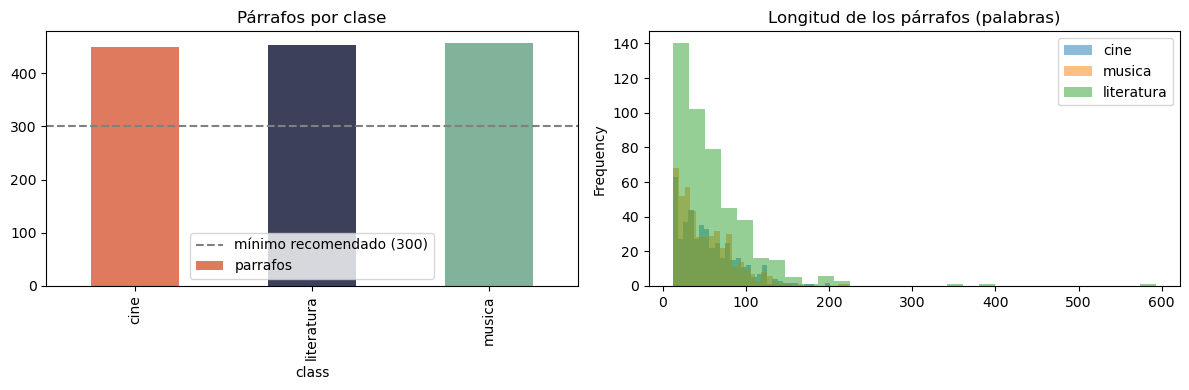

In [8]:
df["n_palabras"] = df["text"].str.split().str.len()

resumen = df.groupby("class").agg(parrafos=("text", "count"),
                                  palabras_media=("n_palabras", "mean")).round(1)
if "article" in df.columns:              # el CSV de GitHub solo trae text;class (contrato)
    resumen["articulos"] = df.groupby("class")["article"].nunique()
display(resumen)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
resumen["parrafos"].plot(kind="bar", ax=ejes[0], color=["#e07a5f", "#3d405b", "#81b29a"])
ejes[0].set_title("Párrafos por clase")
ejes[0].axhline(300, color="grey", linestyle="--", label="mínimo recomendado (300)")
ejes[0].legend()
for clase in df["class"].unique():
    df.loc[df["class"] == clase, "n_palabras"].plot(kind="hist", bins=30, alpha=0.5,
                                                    ax=ejes[1], label=clase)
ejes[1].set_title("Longitud de los párrafos (palabras)")
ejes[1].legend()
plt.tight_layout()
plt.show()

### 1.4 Ruido en las etiquetas
Al heredar la etiqueta del artículo, aparecen párrafos **genéricos** que no hablan realmente del tema (p. ej. biografías: *"Li naskiĝis en 1950 en Parizo"* — "nació en 1950 en París").

Para **medir** este ruido de forma sencilla usamos una lista de **raíces clave** de cada clase (aprovechando que en Esperanto todas las palabras de una familia comparten raíz: *muzik-o, muzik-a, muzik-isto*). Clasificamos cada párrafo en:
- **Claro:** contiene alguna raíz de su clase.
- **Genérico:** no contiene raíces de ninguna clase → no se puede saber el tema solo con él.
- **Confuso:** contiene raíces de otra clase pero no de la suya → posible etiqueta errónea.

In [9]:
RAICES_CLAVE = {
    "cine":       ["film", "kin", "aktor", "reĝisor", "scenar", "kamera", "ekran", "anim"],
    "musica":     ["muzik", "kant", "melodi", "instrument", "orkestr", "komponi", "akord",
                   "ritm", "gitar", "pian", "violon", "tambur", "koncert", "album", "son"],
    "literatura": ["literatur", "roman", "poem", "poezi", "poet", "verk", "libr", "rakont",
                   "aŭtor", "eldon", "novel", "teatr", "dram", "versaĵ"],
}

def contiene_raiz(texto, raices):
    # True si alguna palabra del texto EMPIEZA por alguna de las raíces
    return re.search(r"\b(" + "|".join(raices) + ")", texto.lower()) is not None

def tipo_de_parrafo(fila):
    propia = contiene_raiz(fila["text"], RAICES_CLAVE[fila["class"]])
    otras = any(contiene_raiz(fila["text"], r) for c, r in RAICES_CLAVE.items() if c != fila["class"])
    if propia:
        return "claro"
    return "confuso" if otras else "genérico"

df["ruido"] = df.apply(tipo_de_parrafo, axis=1)
tabla_ruido = pd.crosstab(df["class"], df["ruido"], normalize="index").mul(100).round(1)
display(tabla_ruido)
print(f"Párrafos potencialmente ruidosos (genéricos + confusos): {(df['ruido'] != 'claro').mean():.1%}")

print("\nEjemplos de párrafos genéricos:")
for _, fila in df[df["ruido"] == "genérico"].sample(3, random_state=SEMILLA).iterrows():
    print(f"  [{fila['class']}] {fila['text'][:160]}...")

ruido,claro,confuso,genérico
class,,,
cine,78.2,4.7,17.1
literatura,67.3,3.1,29.6
musica,78.3,2.4,19.3


Párrafos potencialmente ruidosos (genéricos + confusos): 25.4%

Ejemplos de párrafos genéricos:
  [literatura] Inter rimoj oni povas ĉefe distingi inter komenca rimo kaj fina rimo....
  [literatura] Alice Monroe - La pli juna fratino. Milda kaj sentema, kun brilaj okuloj. Ŝi estas la filino de Monroe de lia dua edzino....
  [musica] Por la plej alta registro ne ekzistas unuecaj nomoj. Respektiva bekfluto nomiĝas etbekfluto. La nomoj de la registroj sube de la grandbaso ankaŭ estas malunueca...


---
## 2. Fase 2 — Modelo de NLP para Esperanto

Programamos desde cero (sin spaCy, NLTK ni similares) un modelo **basado en reglas**. Aprovechamos que el Esperanto es una lengua **regular y sin excepciones**: la terminación de cada palabra indica su categoría gramatical.

| Terminación | Categoría (POS) | Ejemplo | Lema |
|---|---|---|---|
| `-o`, `-oj`, `-on`, `-ojn` | sustantivo (`NOUN`) | *librojn* (libros, OD) | *libro* |
| `-a`, `-aj`, `-an`, `-ajn` | adjetivo (`ADJ`) | *bonajn* | *bona* |
| `-e`, `-en` | adverbio (`ADV`) | *rapide* | *rapide* |
| `-i`, `-as`, `-is`, `-os`, `-us`, `-u` | verbo (`VERB`) | *kantis* (cantó) | *kanti* |

Las palabras **cerradas** (artículo, preposiciones, conjunciones, pronombres, correlativos, números...) no siguen estas reglas, así que las reconocemos con un **diccionario**. Usamos la lista de palabras vacías del repositorio guía de la asignatura (`vortoj.json`), que además trae la categoría gramatical de cada palabra.

**API similar a spaCy:**
```python
nlp = Esperanto()               # equivalente a spacy.load(...)
doc = nlp("La knaboj kantis belajn kantojn.")
for token in doc:
    print(token.text, token.lemma_, token.pos_, token.morph, token.is_stop)
```

Componentes: **tokenizador → etiquetador POS + lematizador (morfología) → gestión de stop-words**, con objetos `Doc` y `Token`.

In [10]:
URL_VORTOJ = "https://raw.githubusercontent.com/jparisu/nlp-esperantilo/main/resources/esperanto/vortoj.json"

# Copia de respaldo de vortoj.json (por si GitHub no responde), agrupada por categoría
VORTOJ_RESPALDO = {
    "artikolo":   ["la"],
    "prepozicio": ["al", "anstataŭ", "antaŭ", "apud", "da", "de", "dum", "ekster", "el", "en",
                   "inter", "je", "kontraŭ", "krom", "kun", "laŭ", "malgraŭ", "per", "po", "por",
                   "post", "preter", "pri", "pro", "sen", "sub", "super", "sur", "tra", "trans",
                   "ĉe", "ĉirkaŭ", "ĝis"],
    "konjunkcio": ["aŭ", "do", "kaj", "ke", "kvankam", "kvazaŭ", "nek", "ol", "se", "sed",
                   "tamen", "ĉar"],
    "adverbo":    ["ankaŭ", "ankoraŭ", "apenaŭ", "baldaŭ", "eble", "ekzemple", "eĉ", "for",
                   "hieraŭ", "hodiaŭ", "jam", "male", "morgaŭ", "nepre", "nun", "nur", "plej",
                   "pli", "plu", "preskaŭ", "supre", "tre", "tro", "tuj", "tute", "verŝajne", "ĵus"],
    "partikulo":  ["ajn", "des", "ja", "jen", "jes", "ju", "ne", "ĉi", "ĉu"],
    "pronomo":    ["ci", "ili", "li", "mem", "mi", "ni", "oni", "si", "vi", "ĝi", "ŝi"],
    "nombro":     ["cent", "dek", "du", "kvar", "kvin", "mil", "minus", "naŭ", "nul", "ok",
                   "plus", "sep", "ses", "tri", "unu"],
    "interjekcio": ["ha", "he", "ho", "hu", "nu", "ve"],
    "verboformo": ["esti", "havi", "povi"],
    "titolo":     ["doktoro", "fraŭlo", "sinjoro"],
    "ĝentilaĵo":  ["adiaŭ", "bonvoli"],
}

def cargar_vortoj():
    # Devuelve un diccionario {palabra: categoría} con las palabras vacías del Esperanto.
    try:
        respuesta = requests.get(URL_VORTOJ, headers=CABECERAS, timeout=15)
        respuesta.raise_for_status()
        datos = respuesta.json()
        vortoj = {v["vorto"]: v["kategorio"] for v in datos["vortoj"] if v.get("ignorinda", True)}
        print(f"vortoj.json descargado de GitHub: {len(vortoj)} palabras vacías")
    except Exception as error:
        print("⚠ No se pudo descargar vortoj.json, usamos la copia de respaldo:", error)
        vortoj = {p: cat for cat, lista in VORTOJ_RESPALDO.items() for p in lista}
    return vortoj

VORTOJ = cargar_vortoj()

# Categoría del diccionario → etiqueta POS universal (las mismas que usa spaCy)
CATEGORIA_A_POS = {"artikolo": "DET", "prepozicio": "ADP", "konjunkcio": "CCONJ",
                   "adverbo": "ADV", "partikulo": "PART", "pronomo": "PRON",
                   "nombro": "NUM", "interjekcio": "INTJ"}
SUBORDINANTES = {"ke", "se", "ĉar", "kvankam", "kvazaŭ", "ol"}   # conjunciones subordinantes

# Pronombres personales: forma → lema (mi, min) y posesivos (mia, miaj, mian, miajn)
PRONOMBRES = ["mi", "vi", "li", "ŝi", "ĝi", "ni", "ili", "oni", "si", "ci"]
FORMAS_PRONOMBRE = {}
for p in PRONOMBRES:
    FORMAS_PRONOMBRE[p] = (p, "PRON")
    FORMAS_PRONOMBRE[p + "n"] = (p, "PRON")
    for final in ["a", "aj", "an", "ajn"]:
        FORMAS_PRONOMBRE[p + final] = (p + "a", "DET")

# Correlativos: tabla de 5 prefijos x 9 terminaciones (kio, tiu, ĉiam, neniel...)
PREFIJOS_CORRELATIVOS = ["ki", "ti", "i", "ĉi", "neni"]
FINALES_CORRELATIVOS = {"o": "PRON", "u": "PRON", "a": "DET", "es": "DET", "e": "ADV",
                        "am": "ADV", "al": "ADV", "el": "ADV", "om": "ADV"}
CORRELATIVOS = {}
for prefijo in PREFIJOS_CORRELATIVOS:
    for final, pos in FINALES_CORRELATIVOS.items():
        lema = prefijo + final
        formas = [lema]
        if final in ("u", "a"):
            formas += [lema + "j", lema + "n", lema + "jn"]
        elif final in ("o", "e"):
            formas += [lema + "n"]
        for forma in formas:
            CORRELATIVOS[forma] = (lema, pos)

# Conjunto final de stop-words (se comprueban sobre el LEMA de cada palabra)
STOP_WORDS = set(VORTOJ) | set(PRONOMBRES) | {p + "a" for p in PRONOMBRES} \
             | {lema for lema, _ in CORRELATIVOS.values()}
print(f"Total de stop-words: {len(STOP_WORDS)} | correlativos generados: {len(CORRELATIVOS)} formas")

vortoj.json descargado de GitHub: 122 palabras vacías
Total de stop-words: 177 | correlativos generados: 85 formas


In [11]:
class Token:
    # Una palabra o signo de puntuación analizado (equivalente a spacy.tokens.Token).
    def __init__(self, text, i, lemma_, pos_, morph, is_stop):
        self.text = text          # texto original
        self.i = i                # posición dentro del documento
        self.lemma_ = lemma_      # lema (forma de diccionario)
        self.pos_ = pos_          # categoría gramatical (NOUN, VERB, ADJ...)
        self.morph = morph        # rasgos morfológicos, p. ej. "Case=Acc|Number=Plur"
        self.is_stop = is_stop    # ¿es una palabra vacía?
        self.is_punct = pos_ == "PUNCT"
        self.is_alpha = text.replace("'", "").replace("-", "").isalpha()
        self.like_num = pos_ == "NUM"

    def __repr__(self):
        return self.text


class Doc:
    # Secuencia de tokens de un texto (equivalente a spacy.tokens.Doc).
    def __init__(self, text, tokens):
        self.text = text
        self.tokens = tokens

    def __iter__(self):                 # permite: for token in doc
        return iter(self.tokens)

    def __len__(self):                  # permite: len(doc)
        return len(self.tokens)

    def __getitem__(self, indice):      # permite: doc[0], doc[2:5]
        return self.tokens[indice]

    def __repr__(self):
        return self.text

    @property
    def sents(self):
        # Divide el documento en oraciones (listas de tokens) usando . ! ?
        oracion = []
        for token in self.tokens:
            oracion.append(token)
            if token.text in {".", "!", "?"}:
                yield oracion
                oracion = []
        if oracion:
            yield oracion

    def to_dataframe(self):
        # Tabla con el análisis de cada token (útil para visualizar)
        return pd.DataFrame([{"text": t.text, "lemma_": t.lemma_, "pos_": t.pos_,
                              "morph": t.morph, "is_stop": t.is_stop} for t in self.tokens])

In [12]:
class Esperanto:
    # Modelo de NLP para Esperanto basado en reglas (equivalente a spacy.load(...)).
    # Uso:  nlp = Esperanto();  doc = nlp("texto")

    # Token = "l'" (artículo elidido) | número | palabra (con guiones) | signo de puntuación
    PATRON_TOKEN = re.compile(r"[Ll]'(?=\s|$)|\d+(?:[.,]\d+)*|\w+(?:-\w+)*|[^\w\s]")
    SISTEMA_X = {"cx": "ĉ", "gx": "ĝ", "hx": "ĥ", "jx": "ĵ", "sx": "ŝ", "ux": "ŭ"}
    FINALES_VERBO = {"as": "Tense=Pres", "is": "Tense=Past", "os": "Tense=Fut",
                     "us": "Mood=Cnd", "u": "Mood=Imp", "i": "VerbForm=Inf"}

    def __init__(self):
        self.stop_words = STOP_WORDS
        self.pipe_names = ["tokenizer", "tagger_lemmatizer", "stop_words"]

    # ---------- 1. Tokenizador ----------
    def normalizar(self, texto):
        # Unicode NFC y conversión del "sistema x" (cx → ĉ) usado en teclados sin diacríticos
        texto = unicodedata.normalize("NFC", texto)
        for x, letra in self.SISTEMA_X.items():
            texto = texto.replace(x, letra).replace(x.capitalize(), letra.upper())
        return texto

    def tokenizar(self, texto):
        return self.PATRON_TOKEN.findall(self.normalizar(texto))

    # ---------- 2. Etiquetador POS + lematizador ----------
    def analizar_palabra(self, palabra, inicio_frase):
        # Devuelve (lema, pos, morfología) de una palabra aplicando reglas en orden.
        p = palabra.lower()

        # a) Puntuación y números escritos con cifras
        if not any(c.isalnum() for c in p):
            return palabra, "PUNCT", ""
        if p[0].isdigit():
            return palabra, "NUM", ""

        # b) Palabras cerradas: artículo, correlativos, pronombres y diccionario vortoj.json
        if p in ("la", "l'"):
            return "la", "DET", "Definite=Def"
        if p in CORRELATIVOS:
            lema, pos = CORRELATIVOS[p]
            return lema, pos, ("Case=Acc" if p.endswith("n") else "")
        if p in FORMAS_PRONOMBRE:
            lema, pos = FORMAS_PRONOMBRE[p]
            return lema, pos, ("Case=Acc" if p.endswith("n") else "")
        if p in VORTOJ and VORTOJ[p] in CATEGORIA_A_POS:
            pos = "SCONJ" if p in SUBORDINANTES else CATEGORIA_A_POS[VORTOJ[p]]
            return p, pos, ""
        if re.fullmatch(r"(du|tri|kvar|kvin|ses|sep|ok|naŭ)(dek|cent)", p):   # dudek, tricent...
            return p, "NUM", ""

        # c) Nombre propio: mayúscula en mitad de la frase (Parizo, Zamenhof...)
        if palabra[0].isupper() and not inicio_frase:
            return palabra, "PROPN", ""

        # d) Verbos: se cambia la terminación de tiempo/modo por -i (kantis → kanti)
        for final, rasgo in self.FINALES_VERBO.items():
            if p.endswith(final) and len(p) - len(final) >= 2:
                return p[:-len(final)] + "i", "VERB", rasgo

        # e) Sustantivos y adjetivos: raíz + o/a + (j) + (n)  → librojn = libr + o + j + n
        m = re.fullmatch(r"(.{2,}?)([oa])(j?)(n?)", p)
        if m:
            raiz, vocal, plural, acusativo = m.groups()
            pos = "NOUN" if vocal == "o" else "ADJ"
            morph = "Case=" + ("Acc" if acusativo else "Nom") + "|Number=" + ("Plur" if plural else "Sing")
            return raiz + vocal, pos, morph

        # f) Adverbios derivados: raíz + e + (n)  → rapide, hejmen
        m = re.fullmatch(r"(.{2,}?)e(n?)", p)
        if m:
            return m.group(1) + "e", "ADV", ("Case=Acc" if m.group(2) else "")

        # g) Cualquier otra cosa (palabras extranjeras, siglas...)
        return p, "X", ""

    # ---------- 3. Pipeline completo ----------
    def __call__(self, texto):
        tokens = []
        palabras = self.tokenizar(texto)
        for i, palabra in enumerate(palabras):
            inicio_frase = i == 0 or palabras[i - 1] in {".", "!", "?", ":", "\"", "“", "«", "(", "—", "–"}
            lema, pos, morph = self.analizar_palabra(palabra, inicio_frase)
            es_stop = lema.lower() in self.stop_words or palabra.lower() in self.stop_words
            tokens.append(Token(palabra, i, lema, pos, morph, es_stop))
        return Doc(texto, tokens)

    def pipe(self, textos):
        # Procesa varios textos (como nlp.pipe de spaCy)
        for texto in textos:
            yield self(texto)


nlp = Esperanto()
print("Modelo creado. Componentes:", nlp.pipe_names)

Modelo creado. Componentes: ['tokenizer', 'tagger_lemmatizer', 'stop_words']


### 2.1 Pruebas del modelo
Analizamos una frase de ejemplo y comprobamos con `assert` que las reglas funcionan en casos conocidos.

In [13]:
frase = "La junaj muzikistoj kantis belajn kantojn, kaj ili ankaŭ verkos novan romanon pri Zamenhof."
doc = nlp(frase)
display(doc.to_dataframe())

print("Oraciones:", [" ".join(t.text for t in s) for s in nlp("Mi legas. Vi aŭskultas muzikon!").sents])
print("Sin stop-words:", [t.lemma_ for t in doc if not t.is_stop and not t.is_punct])

,text,lemma_,pos_,morph,is_stop
0,La,la,DET,Definite=Def,True
1,junaj,juna,ADJ,Case=Nom|Number=Plur,False
2,muzikistoj,muzikisto,NOUN,Case=Nom|Number=Plur,False
3,kantis,kanti,VERB,Tense=Past,False
4,belajn,bela,ADJ,Case=Acc|Number=Plur,False
5,kantojn,kanto,NOUN,Case=Acc|Number=Plur,False
6,",",",",PUNCT,,False
7,kaj,kaj,CCONJ,,True
8,ili,ili,PRON,,True
9,ankaŭ,ankaŭ,ADV,,True


Oraciones: ['Mi legas .', 'Vi aŭskultas muzikon !']
Sin stop-words: ['juna', 'muzikisto', 'kanti', 'bela', 'kanto', 'verki', 'nova', 'romano', 'Zamenhof']


In [14]:
def comprobar(palabra, lema, pos):
    token = nlp(palabra)[0]
    assert (token.lemma_, token.pos_) == (lema, pos), f"{palabra}: {token.lemma_}/{token.pos_} ≠ {lema}/{pos}"

comprobar("librojn", "libro", "NOUN")      # sustantivo plural acusativo
comprobar("bonaj", "bona", "ADJ")          # adjetivo plural
comprobar("kantis", "kanti", "VERB")       # verbo pasado
comprobar("legos", "legi", "VERB")         # verbo futuro
comprobar("rapide", "rapide", "ADV")       # adverbio derivado
comprobar("tiujn", "tiu", "PRON")          # correlativo con -jn
comprobar("lin", "li", "PRON")             # pronombre acusativo
comprobar("miajn", "mia", "DET")           # posesivo
comprobar("kaj", "kaj", "CCONJ")           # conjunción (diccionario)
comprobar("dudek", "dudek", "NUM")         # número compuesto
comprobar("cxambro", "ĉambro", "NOUN")     # sistema x → ĉ
assert nlp("la")[0].is_stop and nlp("lin")[0].is_stop and not nlp("muziko")[0].is_stop
assert [t.text for t in nlp("La Mastro de l' Ringoj.")] == ["La", "Mastro", "de", "l'", "Ringoj", "."]
print("✓ Todas las pruebas del modelo de NLP superadas")

✓ Todas las pruebas del modelo de NLP superadas


1359 párrafos analizados en 0.1 s
Porcentaje de stop-words (sin contar puntuación): 42.2%
Tokens sin categoría (X): 1.9%


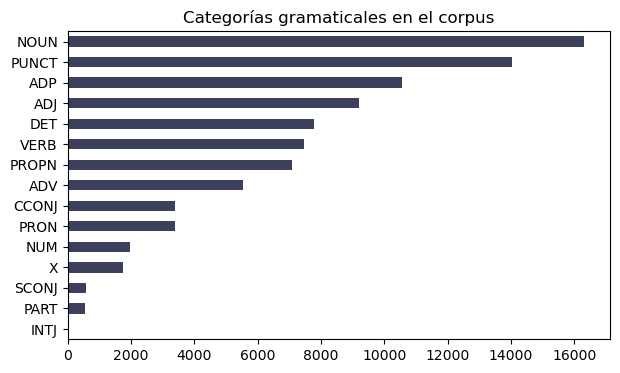

In [15]:
# Aplicamos el modelo a todo el dataset y vemos la distribución de categorías gramaticales
inicio = time.time()
docs = list(nlp.pipe(df["text"]))
print(f"{len(docs)} párrafos analizados en {time.time() - inicio:.1f} s")

conteo_pos = Counter(t.pos_ for d in docs for t in d)
total = sum(conteo_pos.values())
porcentaje_stop = sum(t.is_stop for d in docs for t in d if not t.is_punct) / \
                  sum(not t.is_punct for d in docs for t in d)
print(f"Porcentaje de stop-words (sin contar puntuación): {porcentaje_stop:.1%}")
print(f"Tokens sin categoría (X): {conteo_pos['X'] / total:.1%}")

pd.Series(conteo_pos).sort_values().plot(kind="barh", figsize=(7, 4), color="#3d405b",
                                         title="Categorías gramaticales en el corpus")
plt.show()

---
## 3. Fase 3 — Clasificación

### 3.1 Preprocesamiento
Siguiendo la metodología de clase (tema *Representación vectorial de textos*):
1. **Tokenización** → `nlp(texto)`
2. **Filtrado** → quitamos stop-words, puntuación, números y palabras de 1-2 letras
3. **Normalización** → minúsculas y **lema** (así *muzikon*, *muzikoj*, *muziko* cuentan como la misma palabra)

In [16]:
def preprocesar(texto):
    # Texto → lista de lemas útiles (sin stop-words, puntuación ni números)
    return [t.lemma_.lower() for t in nlp(texto)
            if t.is_alpha and not t.is_stop and len(t.text) > 2]

X_lemas = [preprocesar(texto) for texto in df["text"]]
y = df["class"].values

print("Original: ", df["text"].iloc[0][:150])
print("Procesado:", X_lemas[0][:15])

Original:  Domo sur la akvo (Ĥanei ruje ab) estas la dua postrevolucia filmo de la irana reĝisoro Bahman Farman-Ara. Ĝi aperis en 2001 kaj estas 111 minutojn lon
Procesado: ['domo', 'akvo', 'ĥanei', 'ruje', 'dua', 'postrevolucia', 'filmo', 'irana', 'reĝisoro', 'bahman', 'farman-ara', 'aperi', 'minuto', 'longa']


### 3.2 Vectorización: One-Hot Encoding + media
Usamos la técnica vista en clase: cada lema del vocabulario es una posición de un vector **one-hot**, y el vector del párrafo es la **media** de los vectores de sus palabras:

$$V_{texto} = \frac{1}{N}\sum_{i=1}^{N} V_{palabra_i}$$

Así cada posición indica la **proporción** del texto que ocupa esa palabra, y la longitud del párrafo no influye. El vocabulario se construye **solo con los datos de entrenamiento** (para no filtrar información del test) y nos quedamos con los lemas que aparecen al menos en `min_documentos` párrafos (eliminamos palabras rarísimas que solo añaden ruido y dimensiones).

La implementamos como una clase compatible con `scikit-learn` (`fit` / `transform`) para poder usarla dentro de un `Pipeline` y en validación cruzada.

In [17]:
class VectorizadorOneHotMedia(BaseEstimator, TransformerMixin):
    # Convierte listas de lemas en vectores: media de los vectores one-hot de sus palabras.

    def __init__(self, min_documentos=2, max_palabras=5000):
        self.min_documentos = min_documentos   # nº mínimo de párrafos en que debe aparecer un lema
        self.max_palabras = max_palabras       # tamaño máximo del vocabulario

    def fit(self, X, y=None):
        # Cuenta en cuántos párrafos aparece cada lema y construye el vocabulario
        frecuencia = Counter(lema for lemas in X for lema in set(lemas))
        palabras = [p for p, n in frecuencia.most_common(self.max_palabras) if n >= self.min_documentos]
        self.vocabulario_ = {palabra: posicion for posicion, palabra in enumerate(sorted(palabras))}
        return self

    def transform(self, X):
        matriz = np.zeros((len(X), len(self.vocabulario_)), dtype=np.float32)
        for fila, lemas in enumerate(X):
            conocidos = [l for l in lemas if l in self.vocabulario_]
            for lema in conocidos:
                matriz[fila, self.vocabulario_[lema]] += 1    # suma de vectores one-hot
            if conocidos:
                matriz[fila] /= len(conocidos)               # ... dividida entre N = media
        return matriz


# Ejemplo de las diapositivas de clase, traducido al Esperanto:
# "Dos perros naranjas valen más que un gato y un perro verde"
ejemplo = [preprocesar("Du oranĝaj hundoj valoras pli ol unu kato kaj unu verda hundo.")]
v = VectorizadorOneHotMedia(min_documentos=1).fit(ejemplo)
pd.DataFrame(v.transform(ejemplo), columns=list(v.vocabulario_), index=["texto"]).round(2)

,hundo,kato,oranĝa,valori,verda
texto,0.33,0.17,0.17,0.17,0.17


### 3.3 Partición train / test
Separamos un **20 % de test** que no se toca hasta la evaluación final. Usamos `stratify=y` para que las tres clases tengan la misma proporción en train y test.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X_lemas, y, test_size=0.2, stratify=y, random_state=SEMILLA)
print(f"Train: {len(X_train)} párrafos | Test: {len(X_test)} párrafos")
print("Proporción por clase en test:", dict(Counter(y_test)))

Train: 1087 párrafos | Test: 272 párrafos
Proporción por clase en test: {'musica': 91, 'literatura': 91, 'cine': 90}


### 3.4 Selección del modelo con validación cruzada
Comparamos dos clasificadores vistos en clase, adecuados para texto y muy rápidos (sin GPU):
- **Naive Bayes multinomial**: modelo probabilístico clásico para clasificación de textos.
- **Regresión logística**: modelo lineal que da probabilidades bien calibradas.

Para cada uno hacemos **validación cruzada estratificada de 5 particiones** sobre el train (accuracy y F1 macro). Además, para comprobar que nuestro modelo de NLP **aporta valor**, comparamos con una versión **sin NLP** (palabras tal cual, separando por espacios, sin lematizar ni quitar stop-words).

In [19]:
def sin_nlp(texto):
    # Versión "ingenua" para comparar: minúsculas y separar por espacios, sin lemas ni stop-words
    return re.findall(r"\w+", texto.lower())

X_train_crudo = [sin_nlp(t) for t in df["text"]]
X_train_crudo, _, _, _ = train_test_split(X_train_crudo, y, test_size=0.2, stratify=y, random_state=SEMILLA)

modelos = {
    "Naive Bayes": MultinomialNB(alpha=0.01),
    "Regresión logística": LogisticRegression(C=100, max_iter=2000),
}
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

resultados = []
inicio = time.time()
for nombre, modelo in modelos.items():
    for representacion, X_rep in [("con NLP (lemas)", X_train), ("sin NLP (palabras)", X_train_crudo)]:
        pipeline = Pipeline([("vectorizador", VectorizadorOneHotMedia()), ("modelo", modelo)])
        cv = cross_validate(pipeline, X_rep, y_train, cv=validacion, scoring=["accuracy", "f1_macro"])
        resultados.append({"modelo": nombre, "representación": representacion,
                           "accuracy": cv["test_accuracy"].mean(),
                           "f1_macro": cv["test_f1_macro"].mean(),
                           "f1_macro_std": cv["test_f1_macro"].std()})

tabla_cv = pd.DataFrame(resultados).sort_values("f1_macro", ascending=False).round(3)
display(tabla_cv)
print(f"Tiempo total de validación cruzada: {time.time() - inicio:.1f} s")

,modelo,representación,accuracy,f1_macro,f1_macro_std
0,Naive Bayes,con NLP (lemas),0.869,0.869,0.021
2,Regresión logística,con NLP (lemas),0.865,0.865,0.017
1,Naive Bayes,sin NLP (palabras),0.862,0.861,0.016
3,Regresión logística,sin NLP (palabras),0.791,0.792,0.011


Tiempo total de validación cruzada: 11.5 s


In [20]:
# Ambos modelos obtienen un F1 muy parecido con NLP. Elegimos la regresión logística porque
# sus probabilidades son más informativas: Naive Bayes espera recuentos de palabras y, con
# nuestros vectores de medias (que suman 1), da probabilidades casi planas (p. ej. 0.40/0.39/0.21).
# En la clasificación de páginas web necesitamos precisamente la probabilidad de cada categoría.
con_nlp = tabla_cv[tabla_cv["representación"] == "con NLP (lemas)"].set_index("modelo")
print(con_nlp[["accuracy", "f1_macro", "f1_macro_std"]])
mejor = "Regresión logística"
print("\nModelo elegido:", mejor)

clasificador = Pipeline([("vectorizador", VectorizadorOneHotMedia()), ("modelo", modelos[mejor])])
inicio = time.time()
clasificador.fit(X_train, y_train)
print(f"Entrenamiento: {time.time() - inicio:.2f} s | "
      f"Tamaño del vocabulario: {len(clasificador.named_steps['vectorizador'].vocabulario_)} lemas")

                     accuracy  f1_macro  f1_macro_std
modelo                                               
Naive Bayes             0.869     0.869         0.021
Regresión logística     0.865     0.865         0.017

Modelo elegido: Regresión logística


Entrenamiento: 1.85 s | Tamaño del vocabulario: 3845 lemas


### 3.5 Evaluación final sobre el conjunto de test

Accuracy: 0.857
F1 macro: 0.856

              precision    recall  f1-score   support

        cine      0.860     0.822     0.841        90
  literatura      0.862     0.824     0.843        91
      musica      0.848     0.923     0.884        91

    accuracy                          0.857       272
   macro avg      0.857     0.856     0.856       272
weighted avg      0.857     0.857     0.856       272



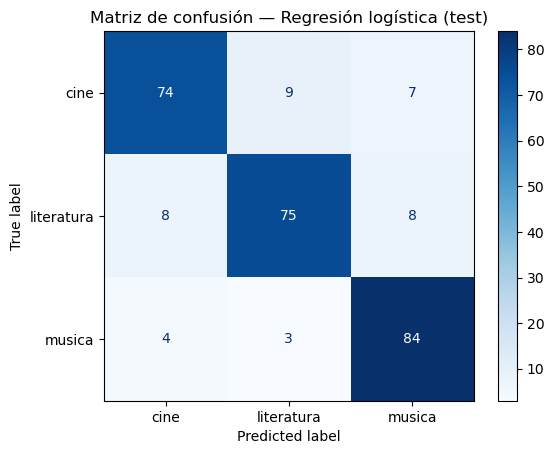

In [21]:
y_pred = clasificador.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"F1 macro: {f1_score(y_test, y_pred, average='macro'):.3f}\n")
print(classification_report(y_test, y_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title(f"Matriz de confusión — {mejor} (test)")
plt.show()

In [22]:
# ¿Qué lemas pesan más para cada clase? (interpretabilidad del modelo)
vocabulario = np.array(list(clasificador.named_steps["vectorizador"].vocabulario_))
modelo = clasificador.named_steps["modelo"]
pesos = modelo.feature_log_prob_ if hasattr(modelo, "feature_log_prob_") else modelo.coef_

top = {}
for indice, clase in enumerate(modelo.classes_):
    # peso relativo: cuánto más pesa el lema en esta clase que en la media de las clases
    relativo = pesos[indice] - pesos.mean(axis=0)
    top[clase] = vocabulario[np.argsort(relativo)[::-1][:12]]
pd.DataFrame(top)

,cine,literatura,musica
0,filmo,romano,muziko
1,leo,libro,instrumento
2,aktoro,literaturo,kordo
3,filmado,direkti,sono
4,orkestro,poezio,muzika
5,reĝisorita,produktita,muzikisto
6,jett,poeto,komponisto
7,kino,poemo,trumpeto
8,bildo,strofo,fluto
9,trek,reĝisoro,kutima


In [23]:
# Análisis de errores: ¿los fallos coinciden con los párrafos ruidosos de la Fase 1?
_, test_idx = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=SEMILLA)
errores = df.iloc[test_idx].assign(prediccion=y_pred)
errores["acierto"] = errores["class"] == errores["prediccion"]

display(errores.groupby("ruido")["acierto"].mean().mul(100).round(1).to_frame("% acierto"))

print("Algunos párrafos mal clasificados:")
for _, fila in errores[~errores["acierto"]].head(4).iterrows():
    print(f"  real={fila['class']:<10} predicho={fila['prediccion']:<10} {fila['text'][:130]}...")

,% acierto
ruido,
claro,92.6
confuso,38.5
genérico,71.4


Algunos párrafos mal clasificados:
  real=literatura predicho=musica     En malpli familiara rilato kun la grupo estis ankaŭ Ernst Jandl kaj Friederike Mayröcker....
  real=cine       predicho=musica     Oni devas neniam produkti la sonon aparte de la bildoj aŭ renversite. (Muzikon oni devas ne uzi krom se ĝi okazas kie la sceno fil...
  real=cine       predicho=literatura Sed iam la mondo aŭdis pri juna knabo nomita Wolfgang Amadeus Mozart, promociita ĉie en Eŭropo fare de lia patro Leopoldo. Lia bri...
  real=literatura predicho=musica     En junio 1957 la grupo prezentis sin unuafoje per voĉlegado monstra ("monsterlesung"). La du literaturkabaredoj ("literarische cab...


In [24]:
def clasificar_texto(texto):
    # Devuelve las probabilidades de cada clase para un texto en Esperanto
    probabilidades = clasificador.predict_proba([preprocesar(texto)])[0]
    return {clase: round(float(p), 3) for clase, p in zip(clasificador.classes_, probabilidades)}

frases = [
    "La reĝisoro filmis la novan filmon kun famaj aktoroj en Holivudo.",      # cine
    "La orkestro ludis simfonion kaj la publiko aplaŭdis la komponiston.",   # música
    "La poeto verkis libron de poemoj kiu gajnis literaturan premion.",      # literatura
]
for frase in frases:
    print(clasificar_texto(frase), "←", frase)

{'cine': 0.984, 'literatura': 0.013, 'musica': 0.003} ← La reĝisoro filmis la novan filmon kun famaj aktoroj en Holivudo.
{'cine': 0.089, 'literatura': 0.002, 'musica': 0.909} ← La orkestro ludis simfonion kaj la publiko aplaŭdis la komponiston.
{'cine': 0.0, 'literatura': 1.0, 'musica': 0.0} ← La poeto verkis libron de poemoj kiu gajnis literaturan premion.


---
## 4. Clasificación de páginas web

Probamos el modelo con **páginas web reales en Esperanto** mediante **web scraping**:
1. Comprobamos el `robots.txt` de la web (buena práctica ética vista en clase).
2. Descargamos el HTML con `requests` (con `timeout` y control de errores).
3. Con `BeautifulSoup` eliminamos menús, scripts, tablas, etc., y extraemos los párrafos `<p>`.
4. Limpiamos los párrafos con la misma función de la Fase 1, clasificamos **cada párrafo** (la misma unidad con la que se entrenó el modelo) y la **probabilidad de cada categoría** para la página es la media de las de sus párrafos.

Usamos artículos de Vikipedio que **excluimos del dataset** (para que el modelo no los haya visto), una web de noticias en Esperanto (*Libera Folio*) y una URL que no existe, para demostrar que el cuaderno **sobrevive a fallos** de las webs.

In [25]:
def permitido_por_robots(url):
    # Consulta el robots.txt de la web. Si no se puede leer, asumimos que está permitido.
    partes = urlparse(url)
    try:
        respuesta = requests.get(f"{partes.scheme}://{partes.netloc}/robots.txt",
                                 headers=CABECERAS, timeout=10)
        if respuesta.status_code != 200:             # la web no tiene robots.txt
            return True
        robots = RobotFileParser()
        robots.parse(respuesta.text.splitlines())
        return robots.can_fetch(CABECERAS["User-Agent"], url)
    except requests.RequestException:
        return True


def extraer_parrafos_web(url):
    # Descarga una página y devuelve sus párrafos de texto limpios.
    respuesta = requests.get(url, headers=CABECERAS, timeout=15)
    respuesta.raise_for_status()                      # lanza error si 404, 500...
    sopa = BeautifulSoup(respuesta.text, "html.parser")
    for etiqueta in sopa(["script", "style", "nav", "header", "footer", "aside", "table", "form"]):
        etiqueta.decompose()                          # quitamos partes que no son contenido
    parrafos = [limpiar_parrafo(p.get_text(" ", strip=True)) for p in sopa.find_all("p")]
    return [p for p in parrafos if len(p.split()) >= MIN_PALABRAS_PARRAFO]


def clasificar_pagina(url):
    # Devuelve un diccionario con las probabilidades de cada clase para la página.
    if not permitido_por_robots(url):
        raise PermissionError("robots.txt no permite descargar esta página")
    parrafos = extraer_parrafos_web(url)
    if not parrafos:
        raise ValueError("la página no tiene párrafos de texto")
    # Clasificamos cada párrafo (la misma unidad con la que se entrenó el modelo)
    # y la probabilidad de la página es la media de las probabilidades de sus párrafos
    probabilidades = clasificador.predict_proba([preprocesar(p) for p in parrafos]).mean(axis=0)
    resultado = {clase: round(float(p), 3) for clase, p in zip(clasificador.classes_, probabilidades)}
    resultado["párrafos"] = len(parrafos)
    return resultado

✓ Vikipedio: Angoroj (película en esperanto): cine


✓ Vikipedio: Ĵazo (jazz): musica


✓ Vikipedio: Hamleto (Hamlet): literatura


✓ Libera Folio (portada, noticias variadas): literatura


⚠ URL inexistente (prueba de robustez): no se pudo clasificar (ConnectionError)


,esperada,cine,literatura,musica,párrafos,predicción
página,,,,,,
Vikipedio: Angoroj (película en esperanto),cine,0.498,0.374,0.128,8,cine
Vikipedio: Ĵazo (jazz),musica,0.096,0.180,0.724,40,musica
Vikipedio: Hamleto (Hamlet),literatura,0.390,0.499,0.111,19,literatura
"Libera Folio (portada, noticias variadas)",—,0.181,0.681,0.138,10,literatura


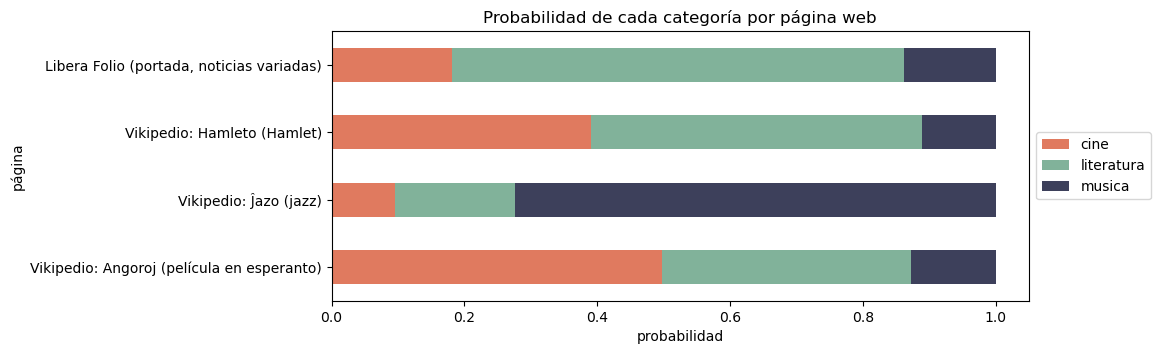

In [26]:
PAGINAS_PRUEBA = [
    # (descripción, URL, clase esperada)
    ("Vikipedio: Angoroj (película en esperanto)", "https://eo.wikipedia.org/wiki/Angoroj", "cine"),
    ("Vikipedio: Ĵazo (jazz)", "https://eo.wikipedia.org/wiki/Ĵazo", "musica"),
    ("Vikipedio: Hamleto (Hamlet)", "https://eo.wikipedia.org/wiki/Hamleto", "literatura"),
    ("Libera Folio (portada, noticias variadas)", "https://www.liberafolio.org/", "—"),
    ("URL inexistente (prueba de robustez)", "https://www.esta-pagina-no-existe-cunef.org/", "—"),
]

filas = []
for descripcion, url, esperada in PAGINAS_PRUEBA:
    try:
        resultado = clasificar_pagina(url)
        prediccion = max(clasificador.classes_, key=lambda c: resultado[c])
        filas.append({"página": descripcion, "esperada": esperada, **resultado, "predicción": prediccion})
        print(f"✓ {descripcion}: {prediccion}")
    except Exception as error:
        # Si una web falla, lo avisamos y seguimos con la siguiente
        print(f"⚠ {descripcion}: no se pudo clasificar ({error.__class__.__name__})")
    time.sleep(1)

resultados_web = pd.DataFrame(filas).set_index("página")
display(resultados_web)

if len(resultados_web) > 0:
    resultados_web[list(clasificador.classes_)].plot(kind="barh", stacked=True, figsize=(9, 3.5),
                                                     color=["#e07a5f", "#81b29a", "#3d405b"])
    plt.title("Probabilidad de cada categoría por página web")
    plt.xlabel("probabilidad")
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    plt.show()

---
## 5. Conclusiones

*(Los números corresponden a nuestra ejecución; pueden variar ligeramente si la Wikipedia cambia y se regenera el dataset.)*

**Fase 1 — Dataset.** Hemos generado automáticamente, mediante la API de Wikipedia, un dataset de **~1.360 párrafos** equilibrado (~450 por clase, de ~240 artículos distintos) que cumple el contrato de datos. Hemos medido el **ruido de etiquetado**: alrededor del **25 %** de los párrafos son genéricos o confusos (sobre todo en literatura, ~30 %). Dos decisiones de diseño mejoraron la calidad: descartar los esbozos muy cortos y las secciones de argumento, que hacían que películas y novelas se confundieran.

**Fase 2 — NLP.** Nuestro modelo basado en reglas (tokenizador, lematizador, POS-tagger y stop-words, con API tipo spaCy) supera todas las pruebas unitarias, analiza el corpus entero en menos de un segundo y solo deja sin categoría (`X`) un **~2 %** de los tokens. Las stop-words son ~42 % de las palabras, lo esperable en un texto real.

**Fase 3 — Clasificación.** Con la vectorización one-hot + media y regresión logística obtenemos en test una **accuracy de ~0,86 y un F1 macro de ~0,86** (validación cruzada: ~0,87), muy por encima del 33 % del azar. El **NLP aporta valor**: con regresión logística, usar lemas sin stop-words sube el F1 de ~0,79 a ~0,87. Las palabras más importantes de cada clase tienen sentido (*filmo, aktoro, kino* / *romano, libro, poezio* / *muziko, instrumento, kordo*). El modelo acierta ~93 % de los párrafos "claros" y mucho menos de los confusos y genéricos: **gran parte de los errores se explica por el ruido del dataset**.

**Páginas web.** El modelo clasifica correctamente las tres páginas de Vikipedio no vistas (*Angoroj* → cine, *Ĵazo* → música, *Hamleto* → literatura). Las probabilidades de *Hamleto* y *Angoroj* están más repartidas entre cine y literatura, lo que refleja que son **categorías cercanas** (Hamlet tiene muchas adaptaciones al cine). La portada de *Libera Folio* sale como literatura, coherente con que trata sobre todo de la lengua y publicaciones. La URL inexistente se gestiona sin detener el cuaderno.

### Limitaciones y posibles mejoras
- **Ruido de etiquetado:** los párrafos heredan la etiqueta del artículo, así que hay párrafos genéricos (biografías, fechas, lugares) que no hablan del tema. Se podría filtrar con las raíces clave o revisar manualmente una muestra.
- **Lematizador:** no descompone afijos (*mal-*, *-ist-*, *-ej-*...): *muzikisto* (músico) y *muziko* (música) son lemas distintos. Tampoco trata los participios (*-anta*, *-ita*...) ni los nombres propios al inicio de frase.
- **Partición:** párrafos de un mismo artículo pueden caer en train y en test, lo que puede hacer las métricas algo optimistas; se podría separar por artículo (`GroupShuffleSplit`). La prueba con páginas no vistas compensa en parte esta limitación.
- **Vocabulario con nombres propios:** algunos lemas importantes son títulos o nombres (*trek* de *Star Trek*, *leo*); con más datos pesarían menos.
- **Vectorización:** el one-hot no capta sinónimos ni contexto; con *embeddings* (p. ej. FastText tiene vectores en Esperanto) el modelo podría generalizar mejor.
- **Reproducibilidad:** la Wikipedia cambia con el tiempo; por eso guardamos el dataset generado en GitHub y fijamos la semilla.

### Uso de herramientas de IA
Hemos usado herramientas de IA gratuitas como apoyo (dudas de sintaxis, revisión de errores y redacción). Todo el código ha sido revisado y entendido por el equipo, que puede explicar cada decisión.